(442, 11)
Giá trị thiếu: 0
        count          mean        std  ...         50%         75%         max
age     442.0 -2.511817e-19   0.047619  ...    0.005383    0.038076    0.110727
sex     442.0  1.230790e-17   0.047619  ...   -0.044642    0.050680    0.050680
bmi     442.0 -2.245564e-16   0.047619  ...   -0.007284    0.031248    0.170555
bp      442.0 -4.797570e-17   0.047619  ...   -0.005670    0.035644    0.132044
s1      442.0 -1.381499e-17   0.047619  ...   -0.004321    0.028358    0.153914
s2      442.0  3.918434e-17   0.047619  ...   -0.003819    0.029844    0.198788
s3      442.0 -5.777179e-18   0.047619  ...   -0.006584    0.029312    0.181179
s4      442.0 -9.042540e-18   0.047619  ...   -0.002592    0.034309    0.185234
s5      442.0  9.293722e-17   0.047619  ...   -0.001947    0.032432    0.133597
s6      442.0  1.130318e-17   0.047619  ...   -0.001078    0.027917    0.135612
target  442.0  1.521335e+02  77.093005  ...  140.500000  211.500000  346.000000

[11 rows x 8

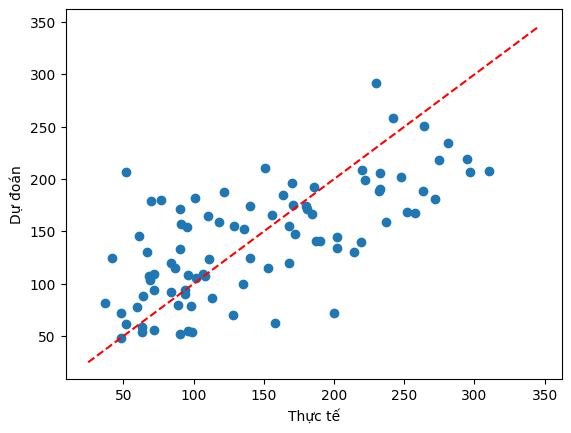

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score


df = load_diabetes(as_frame=True).frame
print(df.shape)
print("Giá trị thiếu:", df.isna().sum().sum())
print(df.describe().T)
print(df.corr()['target'].drop('target').sort_values(ascending=False))


X = df.drop(columns='target')
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


model = LinearRegression()
model.fit(X_train, y_train)
print(pd.Series(model.coef_, index=X.columns).round(1))


y_pred = model.predict(X_test)
print("MSE: %.2f" % mean_squared_error(y_test, y_pred))
print("R2 : %.3f" % r2_score(y_test, y_pred))


plt.scatter(y_test, y_pred)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel('Thực tế'); plt.ylabel('Dự đoán'); plt.show()